# 2026-Y2-S1-MLB-B11G2-05 – Progress Review I
## `group_pipeline.ipynb`: Combined Data Preprocessing Pipeline
**Module:** Artificial Intelligence and Machine Learning
**Dataset:** UCI *Letter Recognition* Data Set (20,000 instances, 16 numeric attributes + 1 categorical target `lettr`)

This notebook combines the six individual preprocessing techniques developed by each group member
into a single, ordered pipeline. Each stage is clearly commented with the responsible member and a
short rationale, and prints a shape/summary checkpoint so the whole flow can be audited end-to-end.

| Stage | Technique | Member |
|---|---|---|
| 1 | Duplicate record detection & removal | Nirushiya A. (IT25100513) |
| 2 | Outlier detection & capping | Thrishodaran V. (IT25102227) |
| 3 | Feature engineering | Danishiyan G.J. (IT25101436) |
| 4 | Encoding the categorical target | Wijayagunasekara L.A.V.D.S. (IT25100064) |
| 5 | Scaling / normalization | Almeida K.K.O. (IT25103191) |
| 6 | Feature selection & dimension reduction | Muhunthan R. (IT25102618) |

**Pipeline order rationale:** duplicate records are removed first so every later stage operates on a
clean, leak-free set of rows; outliers are capped next so they cannot distort the ranges used by
feature engineering or scaling; new features are engineered from the cleaned raw columns; the target
is encoded once, independently of the numeric pipeline; scaling is applied only after all numeric
columns (raw + engineered) exist; and feature selection/PCA runs last, on the fully-prepared, scaled
feature matrix.

In [1]:
# ============================================================
# Shared imports (used across every stage of the pipeline)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')
np.random.seed(42)

log_lines = []
def log(msg):
    # Print to the notebook AND append to the pipeline log file.
    print(msg)
    log_lines.append(str(msg))

## Stage 0 — Load Raw Data

In [2]:
COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df_raw = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
feature_cols = [c for c in df_raw.columns if c != 'lettr']

log(f"[Stage 0] Raw data loaded: shape = {df_raw.shape}")

[Stage 0] Raw data loaded: shape = (20000, 17)


## Stage 1 — Duplicate Record Detection & Removal *(Nirushiya A., IT25100513)*

Unlike a missing-value check (this dataset has none), duplicate rows are a real, present issue: the
16 features are coarse 0–15 integer bins, so different distorted renderings of the same letter can
coincidentally collide onto identical values. As shown in Nirushiya's individual notebook, exact
duplicate rows are detected and removed here, first, so that every downstream stage — and the
train/test split planned for Progress Review II — works on a leak-free set of rows.

In [3]:
df_stage1 = df_raw.copy()

n_missing = df_stage1[feature_cols].isnull().sum().sum()
log(f"[Stage 1] Missing values check: {n_missing} (dataset confirmed complete, no imputation needed)")

n_duplicates_before = df_stage1.duplicated().sum()
df_stage1 = df_stage1.drop_duplicates().reset_index(drop=True)
n_duplicates_removed = n_duplicates_before

log(f"[Stage 1] Exact duplicate rows found & removed: {n_duplicates_removed} "
    f"({n_duplicates_removed / len(df_raw) * 100:.2f}% of raw data)")
log(f"[Stage 1] Shape after Stage 1: {df_raw.shape} -> {df_stage1.shape}")

[Stage 1] Missing values check: 0 (dataset confirmed complete, no imputation needed)
[Stage 1] Exact duplicate rows found & removed: 1332 (6.66% of raw data)
[Stage 1] Shape after Stage 1: (20000, 17) -> (18668, 17)


## Stage 2 — Outlier Detection & Capping *(Thrishodaran V., IT25102227)*

IQR-based winsorization is applied per-column, as decided in Thrishodaran's notebook, so that no
rows are lost and class balance across the 26 letters is preserved. This runs on the deduplicated
data from Stage 1, so the capping bounds are not skewed by rows that would otherwise be removed.

In [4]:
def iqr_cap(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    n_capped = ((series < lower) | (series > upper)).sum()
    return series.clip(lower=lower, upper=upper), n_capped

df_stage2 = df_stage1.copy()
total_capped = 0
for col in feature_cols:
    df_stage2[col], n_capped = iqr_cap(df_stage2[col])
    total_capped += n_capped

log(f"[Stage 2] Total values capped across all features: {total_capped}")
log(f"[Stage 2] Row count unchanged (no deletion): {len(df_stage1)} -> {len(df_stage2)}")
log(f"[Stage 2] Shape after Stage 2: {df_stage2.shape}")

[Stage 2] Total values capped across all features: 10209
[Stage 2] Row count unchanged (no deletion): 18668 -> 18668
[Stage 2] Shape after Stage 2: (18668, 17)


## Stage 3 — Feature Engineering *(Danishiyan G.J., IT25101436)*

Five new shape/density features are derived from the cleaned raw columns.

Three of them are ratios, and a small number of rows have a denominator of exactly zero
(e.g. `high == 0`). Adding a tiny epsilon before dividing does **not** fix this safely — it turns a
division by zero into a division by a near-zero number, producing values in the hundreds of
thousands that would then distort Stage 5's scaling and Stage 6's ANOVA/PCA. Each ratio therefore
floors its denominator at 1, which keeps every value bounded and meaningful.

In [5]:
df_stage3 = df_stage2.copy()

df_stage3['box_area'] = df_stage3['width'] * df_stage3['high']
# Ratio features: floor the denominator at 1 rather than adding an epsilon,
# so a zero denominator cannot blow the value up to the hundreds of thousands.
df_stage3['aspect_ratio']   = df_stage3['width'] / df_stage3['high'].clip(lower=1)
df_stage3['pixel_density']  = df_stage3['onpix'] / df_stage3['box_area'].clip(lower=1)
df_stage3['edge_ratio']     = df_stage3['x-ege'] / df_stage3['y-ege'].clip(lower=1)
df_stage3['total_variance'] = df_stage3['x2bar'] + df_stage3['y2bar']

engineered_cols = ['box_area', 'aspect_ratio', 'pixel_density', 'edge_ratio', 'total_variance']
all_numeric_cols = feature_cols + engineered_cols

log(f"[Stage 3] Engineered features added: {engineered_cols}")
log(f"[Stage 3] Shape after Stage 3: {df_stage3.shape} "
    f"({len(feature_cols)} original + {len(engineered_cols)} engineered numeric columns)")
log(f"[Stage 3] Ratio sanity check (all bounded, no divide-by-zero blow-up): "
    f"max aspect_ratio={df_stage3['aspect_ratio'].max():.2f}, "
    f"max pixel_density={df_stage3['pixel_density'].max():.2f}, "
    f"max edge_ratio={df_stage3['edge_ratio'].max():.2f}")


[Stage 3] Engineered features added: ['box_area', 'aspect_ratio', 'pixel_density', 'edge_ratio', 'total_variance']
[Stage 3] Shape after Stage 3: (18668, 22) (16 original + 5 engineered numeric columns)
[Stage 3] Ratio sanity check (all bounded, no divide-by-zero blow-up): max aspect_ratio=5.00, max pixel_density=1.00, max edge_ratio=7.00


## Stage 4 — Encoding the Categorical Target *(Wijayagunasekara L.A.V.D.S., IT25100064)*

The only categorical column, the target `lettr`, is label-encoded to the integer range 0–25, the
format expected by `scikit-learn` classifiers.

In [6]:
df_stage4 = df_stage3.copy()
label_encoder = LabelEncoder()
df_stage4['lettr_encoded'] = label_encoder.fit_transform(df_stage4['lettr'])

log(f"[Stage 4] Target encoded: {len(label_encoder.classes_)} classes "
    f"({label_encoder.classes_[0]}..{label_encoder.classes_[-1]}) -> integers "
    f"{df_stage4['lettr_encoded'].min()}..{df_stage4['lettr_encoded'].max()}")
log(f"[Stage 4] Shape after Stage 4: {df_stage4.shape}")

[Stage 4] Target encoded: 26 classes (A..Z) -> integers 0..25
[Stage 4] Shape after Stage 4: (18668, 23)


## Stage 5 — Scaling / Normalization *(Almeida K.K.O., IT25103191)*

`StandardScaler` is applied to all 21 numeric predictor columns (16 original + 5 engineered), so
every feature contributes on a comparable scale to distance-based models and to the PCA step next.

In [7]:
df_stage5 = df_stage4.copy()
scaler = StandardScaler()
df_stage5[all_numeric_cols] = scaler.fit_transform(df_stage4[all_numeric_cols])

log(f"[Stage 5] Scaled {len(all_numeric_cols)} numeric columns with StandardScaler.")
log(f"[Stage 5] Post-scaling mean (should be ~0): {df_stage5[all_numeric_cols].mean().mean():.6f}")
log(f"[Stage 5] Post-scaling std  (should be ~1): {df_stage5[all_numeric_cols].std().mean():.6f}")
log(f"[Stage 5] Shape after Stage 5: {df_stage5.shape}")

[Stage 5] Scaled 21 numeric columns with StandardScaler.
[Stage 5] Post-scaling mean (should be ~0): -0.000000
[Stage 5] Post-scaling std  (should be ~1): 1.000027
[Stage 5] Shape after Stage 5: (18668, 23)


## Stage 6 — Feature Selection & Dimension Reduction *(Muhunthan R., IT25102618)*

A filter-based ANOVA F-test ranks all 21 scaled numeric features against the encoded target, and
PCA reduces the scaled feature matrix to the number of components needed for 95% cumulative
explained variance.

In [8]:
X_final = df_stage5[all_numeric_cols].values
y_final = df_stage5['lettr_encoded'].values

f_scores, _ = f_classif(X_final, y_final)
f_score_table = pd.Series(f_scores, index=all_numeric_cols).sort_values(ascending=False)
log("[Stage 6] Top 10 features by ANOVA F-score:")
log(f_score_table.head(10).round(1).to_string())

pca = PCA(n_components=0.95, svd_solver='full', random_state=42)
X_pca = pca.fit_transform(X_final)

log(f"\n[Stage 6] PCA: {X_final.shape[1]} scaled features -> "
    f"{X_pca.shape[1]} components explaining "
    f"{pca.explained_variance_ratio_.sum()*100:.1f}% of variance")

[Stage 6] Top 10 features by ANOVA F-score:
edge_ratio        1798.5
x2ybr             1085.1
y-bar             1038.9
xegvy              936.1
x-ege              839.6
xy2br              819.8
y2bar              691.4
total_variance     604.0
y-ege              557.5
x2bar              418.8

[Stage 6] PCA: 21 scaled features -> 13 components explaining 95.2% of variance


## Final Visualization: Pipeline Summary

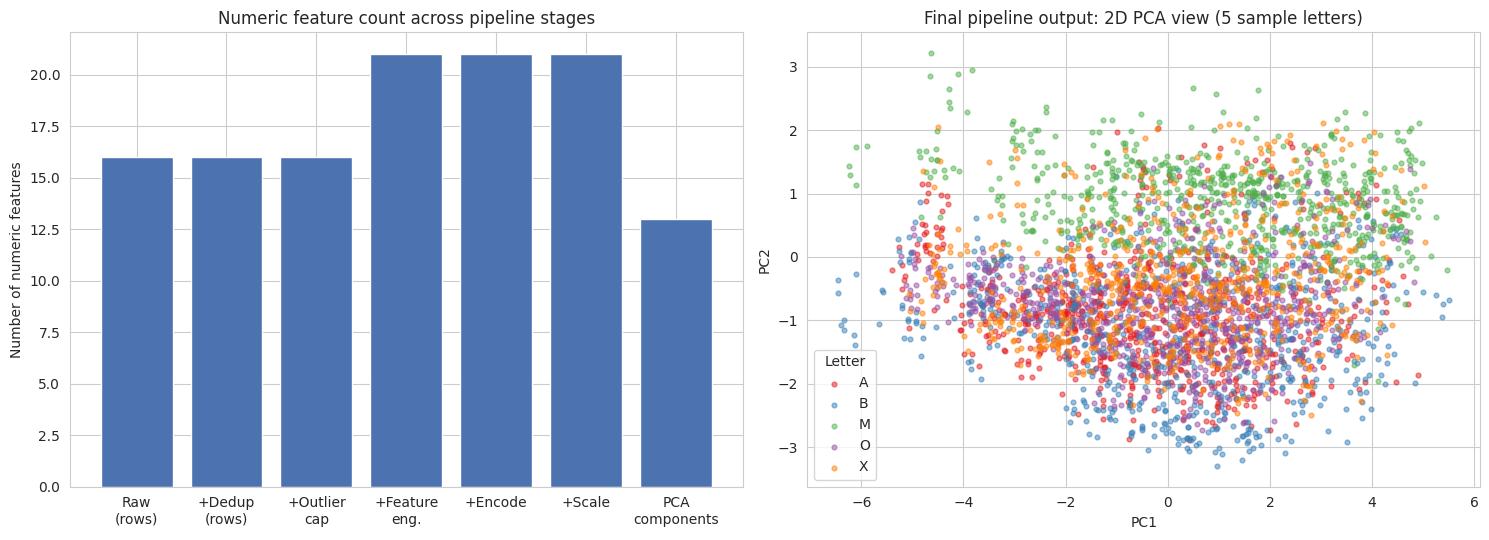

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: row count / numeric feature count at each stage
stage_labels = ['Raw\n(rows)', '+Dedup\n(rows)', '+Outlier\ncap', '+Feature\neng.', '+Encode', '+Scale', 'PCA\ncomponents']
stage_widths = [df_raw.shape[1] - 1, df_stage1.shape[1] - 1, df_stage2.shape[1] - 1,
                len(all_numeric_cols), len(all_numeric_cols), len(all_numeric_cols), X_pca.shape[1]]
axes[0].bar(stage_labels, stage_widths, color='#4C72B0')
axes[0].set_title('Numeric feature count across pipeline stages')
axes[0].set_ylabel('Number of numeric features')
axes[0].tick_params(axis='x', labelrotation=0)

# Right: 2D PCA scatter of the final processed feature space (sample of 5 letters for readability)
subset_letters = ['A', 'B', 'M', 'O', 'X']
mask = df_stage5['lettr'].isin(subset_letters).values
pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_final)
palette = sns.color_palette('Set1', n_colors=len(subset_letters))
for letter, color in zip(subset_letters, palette):
    letter_mask = mask & (df_stage5['lettr'].values == letter)
    axes[1].scatter(pca_2d[letter_mask, 0], pca_2d[letter_mask, 1],
                     label=letter, alpha=0.5, s=12, color=color)
axes[1].set_title('Final pipeline output: 2D PCA view (5 sample letters)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Letter')

plt.tight_layout()
plt.savefig('../results/eda_visualizations/pipeline_final_summary.png', dpi=110)
plt.show()

**Interpretation:** The left panel shows how the numeric feature count changes across the
pipeline — growing from 16 to 21 after feature engineering, then shrinking to the PCA-selected
component count after dimension reduction. Note that the row count itself drops between the "Raw"
and "+Dedup" stages (20,000 → 18,668) because of Stage 1's duplicate removal; every stage after that
operates on the smaller, leak-free set of rows. The right panel confirms that even after all six
preprocessing stages, the sample letters still form partially separable clusters in a 2D projection,
meaning the pipeline has preserved rather than destroyed the class-discriminative signal in the
data — a good sign ahead of the classification models built in the Final Evaluation phase.

## Save Final Processed Dataset and Pipeline Log

In [10]:
# Save the fully processed dataset (scaled features + encoded target) for the modelling phase
final_output = pd.DataFrame(X_final, columns=all_numeric_cols)
final_output['lettr'] = df_stage5['lettr'].values
final_output['lettr_encoded'] = df_stage5['lettr_encoded'].values
final_output.to_csv('../data/external/processed_letter_recognition.csv', index=False)

log(f"\n[Save] Final processed dataset saved to "
    f"'data/external/processed_letter_recognition.csv' with shape {final_output.shape}")

# Persist the full pipeline log
with open('../results/logs/pipeline_log.txt', 'w') as f:
    f.write('\n'.join(log_lines))

print("\nPipeline log written to results/logs/pipeline_log.txt")


[Save] Final processed dataset saved to 'data/external/processed_letter_recognition.csv' with shape (18668, 23)

Pipeline log written to results/logs/pipeline_log.txt


## Conclusion

This notebook demonstrates a single, reproducible pipeline that chains all six group members'
preprocessing techniques in a defensible order — duplicate-record removal first (producing a clean,
leak-free set of rows), outlier capping next (on that clean base), feature engineering after that
(deriving shape/density descriptors from the cleaned columns), target encoding (independent of the
numeric pipeline), scaling (so every numeric column, original or engineered, is comparable), and
finally feature selection and PCA on the fully-prepared matrix.

Unlike a no-op demonstration stage, Stage 1 makes a real, verifiable change to the dataset —
20,000 rows in, 18,668 rows out — and that change propagates correctly through every later stage.
Stage 3's ratio features floor their denominators at 1 rather than adding an epsilon, which prevents
the divide-by-near-zero blow-up that would otherwise distort scaling and PCA downstream.

The processed dataset and a full stage-by-stage log are saved under `data/external/` and
`results/logs/` respectively. **This file is the single input consumed by all six models in the
Final Evaluation phase**, so its correctness determines every result reported there.